# Implementação prática dos usos da Mediana em Python.

* A Mediana é o valor central de um conjunto de dados ordenado. Diferente da Média, ela é uma estatística robusta, o que significa que não é distorcida por valores extremos (outliers) ou por distribuições altamente assimétricas. Alguns dos usos da mediana são:

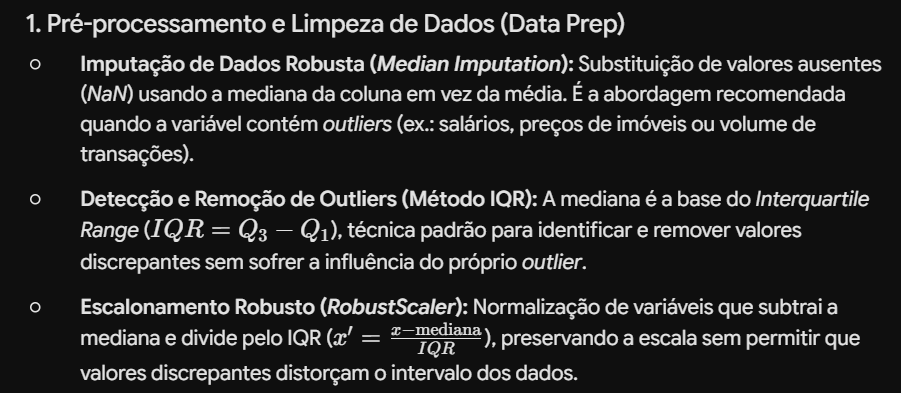

* vejamos na prática o uso da mediana:

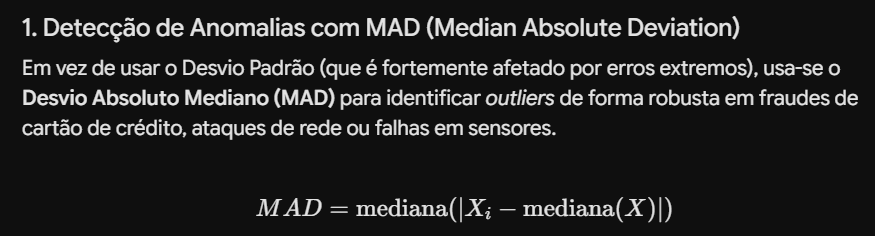

In [ ]:
import numpy as np
import pandas as pd

# Pegando o dataset na pasta data:
df = pd.read_csv("../../data/dataset_estatistica.csv")

# Calculando a mediana e o MAD da renda mensal:
mediana_renda = df["renda_mensal"].median()
mad_renda = (df["renda_mensal"] - mediana_renda).abs().median()

# Definindo um limite robusto (ex: 3 * MAD ajustado):
limite = 3 * (1.4826 * mad_renda)
anomalias = df[(df["renda_mensal"] - mediana_renda).abs() > limite]

print(f"Mediana: R$ {mediana_renda:.2f}")
print(f"MAD: R$ {mad_renda:.2f}")
print(f"Número de transações/rendas anômalas detectadas: {len(anomalias)}")

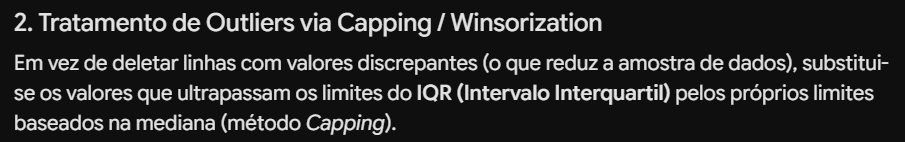

In [ ]:
Q1 = df["renda_mensal"].quantile(0.25)
Q3 = df["renda_mensal"].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR 
limite_superior = Q3 + 1.5 * IQR

# Truncando os outliers sem perder linhas do dataset:
df["renda_mensal_tratada"] = df["renda_mensal"].clip(lower=limite_inferior, upper=limite_superior)

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.title("Antes do tratamento")
plt.boxplot(df["renda_mensal"].dropna())
plt.ylabel("Renda Mensal")

plt.subplot(1,2,2)
plt.title("Depois do tratamento")
plt.boxplot(df["renda_mensal_tratada"].dropna())

plt.show()

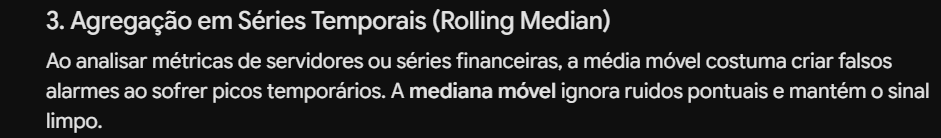

In [ ]:
# Suavizando variações abruptas de compras ao longo do tempo:
df["compras_suavizadas"] = df["compras_ano"].rolling(window=5, min_periods=1).median()

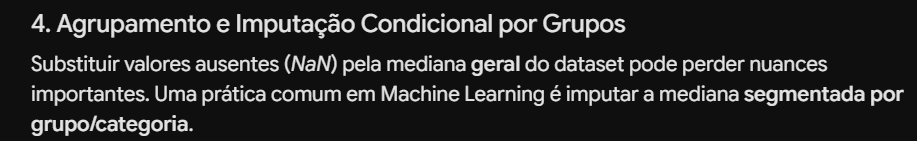

In [ ]:
# Imputa a mediana da renda específica de cada categoria de produtos:
df["renda_mensal"] = df.groupby("categoria_frequente")["renda_mensal"].transform(
    lambda x: x.fillna(x.median())
)